# 06 · TPVFormer → triplane (TPV), step by step

**`TRIPLANE_LIFTERS["tpvformer"]` → `lifting.triplane.TPVFormerTriplaneLifter`**  ·  Huang et al., *Tri-Perspective View for Vision-Based 3D Semantic Occupancy Prediction* (CVPR 2023)

> Natively a triplane lifter: XY + XZ + YZ learned query tokens alternate cross-view hybrid attention (planes talk to each other) and image cross-attention (anchors projected into the cameras).

This notebook shows, cell by cell, how the **TPVFormer** lifting technique produces a
**tri-perspective view** (three orthogonal feature planes `xy` = BEV, `xz`, `yz`) instead of a single
bird's-eye-view map, *without changing a line of the existing BEV lifter* - the triplane module wraps it
(composition) and only adds what is needed to keep the height axis.

| § | what you will see |
|---|---|
| 1 | the idea, the animated step-by-step GIF and a detailed Mermaid diagram |
| 2 | every animation step as a still image |
| 3 | the shared toy scene (4 cameras, vehicles, pedestrians) |
| 4 | building the triplane lifter from the registry |
| 5 | **inside the lifter**: every intermediate tensor, with exact checks |
| 6 | the triplane contract, verified |
| 7 | end-to-end training on 3D semantic occupancy |
| 8 | the negative control: does it really use the cameras? |
| 9 | how to use it in your own code, recap, cheat sheet, exercises |

## 1. The idea

![TPVFormer triplane lifting animation](../../assets/triplane/tpvformer.gif)


TPVFormer *is* the triplane method: it introduced the tri-perspective view. `TPVFormerLifter.lift_planes` already
returns `TPVPlanes`, so `TPVFormerTriplaneLifter` only wraps it (unchanged) and adds a per-plane `1×1` projection so
every triplane lifter shares one contract (`in_channels → out_channels`, BEV from `TriplaneBEVHead`).

Each layer does:

1. **Cross-view hybrid attention** - all `XY + XZ + YZ` tokens form one sequence. A query on one plane fixes two
   coordinates; the third is set to the middle of its axis. The query then samples (deformably) the **same 3D location
   on all three planes** - this is how a pedestrian seen on `xy` informs the height rows of `xz` and `yz`.
2. **Image cross-attention** - like BEVFormer, with anchors along each plane normal projected into the cameras.
3. **Feed-forward**.

Compared with notebook 05 (three independent BEVFormer encoders), the only difference is step 1 - §7 trains both and
compares them.

### Detailed diagram

Colours: <span style="color:#d48806">■ data</span> · <span style="color:#1f77b4">■ fixed geometry</span>
· <span style="color:#8e44ad">■ learned</span> · <span style="color:#2e8b57">■ reused from the existing BEV lifter</span>
· <span style="color:#c0392b">■ outputs</span>. (Mermaid renders in JupyterLab ≥ 4.1, VS Code and on GitHub;
the matplotlib version below renders everywhere.)

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K (B,N,3,3) · cam_to_ego (B,N,4,4)"]:::data
  subgraph CORE["TPVFormerLifter.lift_planes (existing, unchanged)"]
    direction TB
    Q["XY + XZ + YZ learned query tokens"]:::learned --> CVHA["cross-view hybrid attention<br/>each query samples the SAME 3D point<br/>on all three planes"]:::learned
    CVHA --> ICA["image cross-attention<br/>anchors along each plane normal<br/>projected into every camera"]:::learned
    ICA --> FF["feed-forward"]:::learned
    FF -->|"× num_layers"| CVHA
  end
  ENC --> ICA
  CAM --> ICA
  FF --> PP["PlaneProjection (new)<br/>1×1 conv per plane"]:::learned
  PP --> TPV
  TPV["TPVPlanes<br/>xy (B,C,X,Y) · xz (B,C,X,Z) · yz (B,C,Y,Z)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz + yz → fold Z<br/>BEV (B, C, X, Y)"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel logits (B,K,X,Y,Z)<br/>+ point logits (B,K,P)"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations


$$ T = [\,Q_{xy};\ Q_{xz};\ Q_{yz}\,] \in \mathbb{R}^{(XY + XZ + YZ) \times C} $$

$$ \mathrm{CVHA}(t) = \sum_{P \in \{xy, xz, yz\}} \mathrm{DeformAttn}\big(t,\ \rho_P(t),\ P\big), \qquad
\rho_P(t) = \text{the 3D location of } t \text{ expressed in plane } P $$

$$ T \leftarrow \mathrm{FFN}\big(\mathrm{ICA}(\mathrm{CVHA}(T))\big) \quad(\times\ \text{num\_layers}), \qquad
f(x, y, z) = xy(x, y) + xz(x, z) + yz(y, z) $$

| tensor | shape |
|---|---|
| tokens | `(B, XY + XZ + YZ, C)` |
| hybrid reference points | `(XY + XZ + YZ, 3, 2)` - one `(col, row)` per plane |
| projected anchors | per plane `(B, N, Q_P, A_P, 2)` |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import LIFTERS
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_lifter, build_triplane_model, build_triplane_bev_model
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


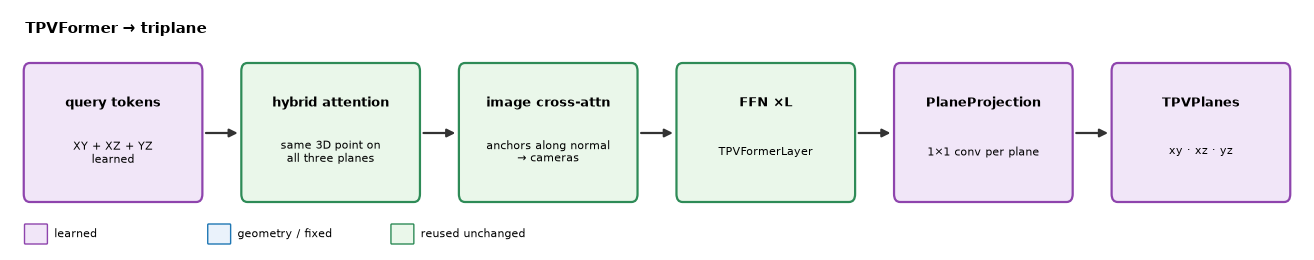

In [2]:
PipelineDiagram('TPVFormer → triplane').extend([
    ('query tokens', 'XY + XZ + YZ\nlearned', 'learned'),
    ('hybrid attention', 'same 3D point on\nall three planes', 'reused'),
    ('image cross-attn', 'anchors along normal\n→ cameras', 'reused'),
    ('FFN ×L', 'TPVFormerLayer', 'reused'),
    ('PlaneProjection', '1×1 conv per plane', 'learned'),
    ('TPVPlanes', 'xy · xz · yz', 'learned'),
]).show()

## 2. The animation, one still per step

The GIF above is rendered by `lifting.triplane.animation` (Pillow only, exact geometry on a toy scene:
4 cameras at the origin, a car, a pedestrian and a pole). `StoryboardViewer` re-renders the **final frame of every
step** so the whole sequence can be read at once. Regenerate all GIFs with `python scripts/make_triplane_gifs.py`.

step 1: Inputs
step 2: Learned plane queries
step 3: 3D anchors along each plane normal
step 4: Project anchors -> reference points
step 5: Cross-view hybrid attention
step 6: Per-plane image cross-attention
step 7: Stack layers -> planes
step 8: Triplane output


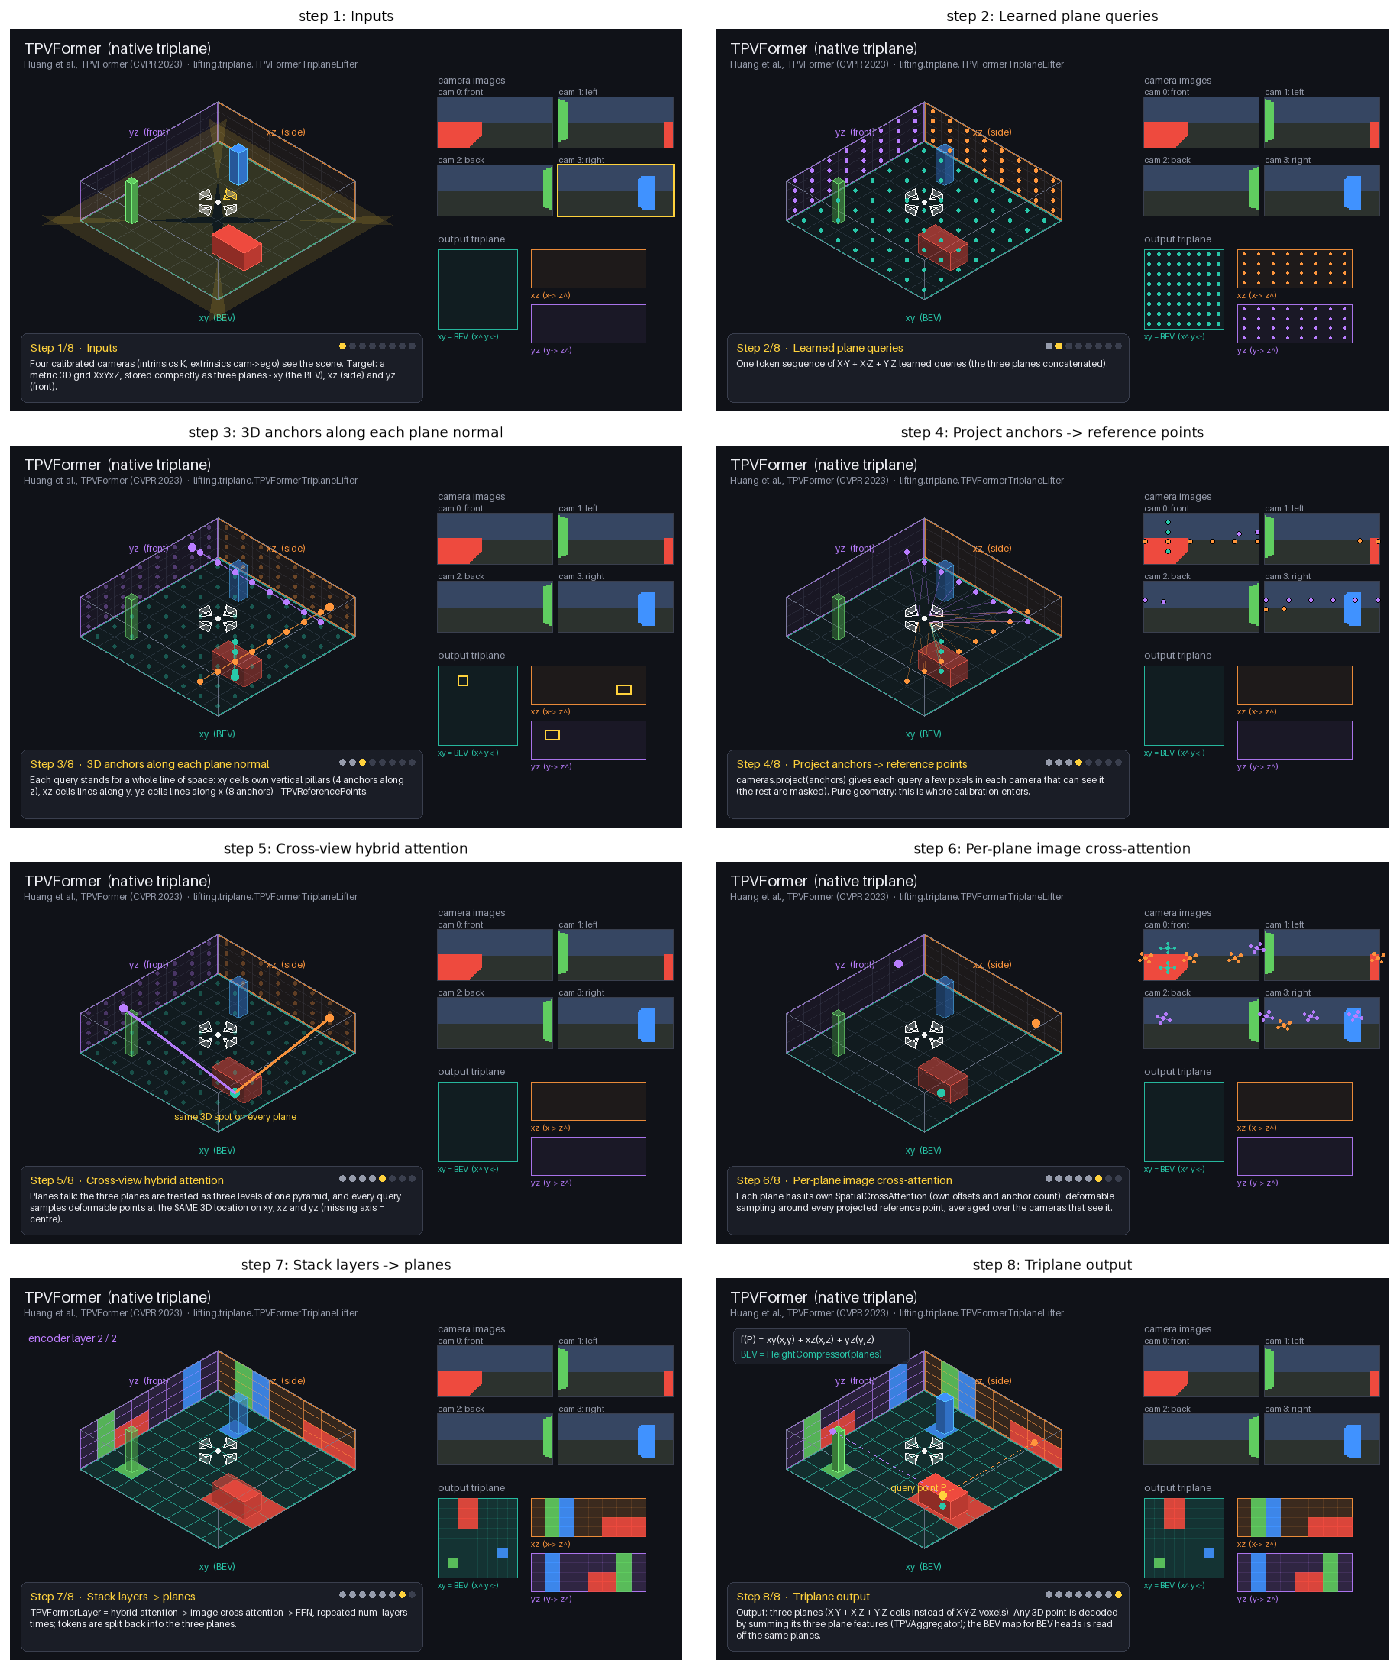

In [3]:
viewer = StoryboardViewer("tpvformer")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

Every triplane notebook uses the same `TriplaneScene`: a `32 m × 32 m × 4 m` region cut into `16 × 16 × 4`
cells, four `48 × 96` cameras whose yaw is **randomly rotated per scene** (so no network can memorise where
"front" is - it must read the calibration), and procedurally placed vehicles (red) and pedestrians (blue).
The ground truth is a 3D occupancy grid `(B, X, Y, Z)`; collapsing it along each axis gives the three
**label planes** each triplane is supervised against.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


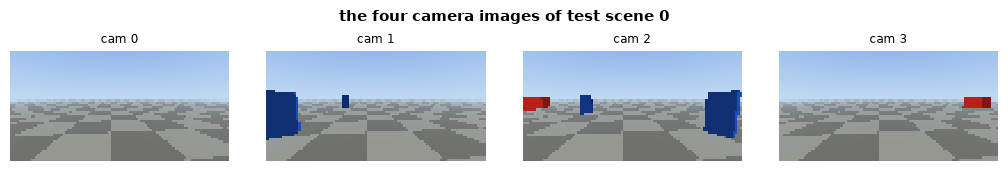

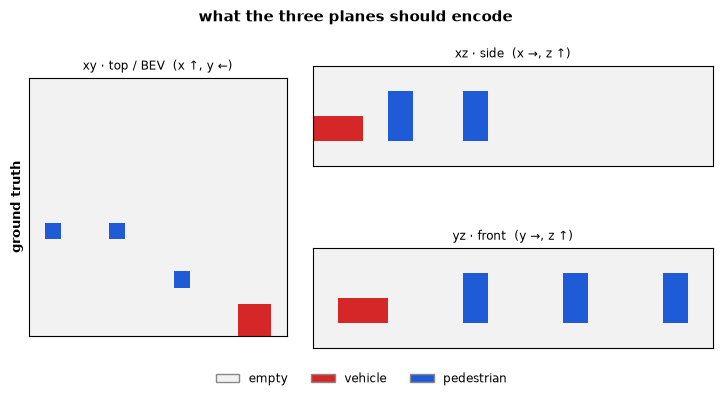

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))], title="what the three planes should encode")

## 4. Build the triplane lifter

Two equivalent ways:

* `TRIPLANE_LIFTERS.build("tpvformer", grid=..., in_channels=..., out_channels=...)` - the raw registry;
* `build_triplane_lifter("tpvformer", grid, channels, image_size, num_cameras, encoder)` - also injects the
  context some lifters need (`feature_size`, `num_cameras`, `depth_bins`), exactly like `lifting.models.build_lifter`
  does for BEV lifters.

The image encoder turns `(B·N, 3, H, W)` images into a feature pyramid (strides 4 and 8 here); every lifter
consumes `(B, N, C, H_l, W_l)` per level.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras
print("feature pyramid:", [tuple(f.shape) for f in features])

lifter = build_triplane_lifter("tpvformer", scene.grid, C, scene.image_size, scene.num_cameras, encoder, num_layers=1)
print(type(lifter).__name__, "| is a BaseLifter too:", isinstance(lifter, BaseLifter))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<12s} {type(child).__name__:<28s} {n:>9,} params")

feature pyramid: [(4, 4, 32, 12, 24), (4, 4, 32, 6, 12)]
TPVFormerTriplaneLifter | is a BaseLifter too: True
parameters: 99,184
  .bev_head     TriplaneBEVHead                 37,984 params
  .core         TPVFormerLifter                 58,032 params
  .projection   PlaneProjection                  3,168 params


## 5. Inside the lifter, step by step

### 5.1 One token sequence for the three planes

In [6]:
core = lifter.core                                       # the existing TPVFormerLifter
REFS = core.references
print(type(core).__name__, "| tokens:", tuple(core.queries.shape), "=", " + ".join(f"{h}x{w}" for h, w in REFS.plane_shapes))
print("layers:", [type(l).__name__ for l in core.layers])
layer = core.layers[0]
for name, mod in layer.named_children():
    print(f"  .{name:<12s} {type(mod).__name__:<28s} {sum(p.numel() for p in mod.parameters()):>8,} params")

TPVFormerLifter | tokens: (384, 32) = 16x16 + 16x4 + 16x4
layers: ['TPVFormerLayer']
  .hybrid_attn  CrossViewHybridAttention        6,864 params
  .cross_attn   ModuleList                     22,176 params
  .ffn          FeedForward                     4,192 params
  .norms        ModuleList                        192 params


### 5.2 Cross-view hybrid attention: the same 3D point on every plane

`hybrid_reference_points()` gives, for every token, its location on each of the three planes as normalised
`(col, row)`. Take an `xy` token: on `xz` and `yz` it points at the **middle height** of its column.

In [7]:
hybrid = REFS.hybrid_reference_points()                 # (Q_total, 3, 2)
print("hybrid reference points:", tuple(hybrid.shape))
nx, ny, nz = scene.grid.resolution
t = 5 * ny + 9                                          # xy token at row x=5, col y=9
print(f"xy token #{t}: on xy (col,row)={hybrid[t, 0].tolist()}, on xz={hybrid[t, 1].tolist()}, on yz={hybrid[t, 2].tolist()}")
t2 = nx * ny + 5 * nz + 3                               # xz token at row x=5, col z=3
print(f"xz token #{t2}: on xy={hybrid[t2, 0].tolist()}, on xz={hybrid[t2, 1].tolist()}, on yz={hybrid[t2, 2].tolist()}")

hybrid reference points: (384, 3, 2)
xy token #89: on xy (col,row)=[0.59375, 0.34375], on xz=[0.5, 0.34375], on yz=[0.5, 0.59375]
xz token #279: on xy=[0.5, 0.34375], on xz=[0.875, 0.34375], on yz=[0.875, 0.5]


### 5.3 Image cross-attention anchors (same geometry as BEVFormer's triplane)

plane xy: anchors (256, 4, 3)  one query: [[1.0, -9.0, -0.5], [1.0, -9.0, 0.5], [1.0, -9.0, 1.5], [1.0, -9.0, 2.5]]
plane xz: anchors (64, 8, 3)  one query: [[1.0, -14.0, 2.5], [1.0, -10.0, 2.5], [1.0, -6.0, 2.5], [1.0, -2.0, 2.5], [1.0, 2.0, 2.5], [1.0, 6.0, 2.5], [1.0, 10.0, 2.5], [1.0, 14.0, 2.5]]
plane yz: anchors (64, 8, 3)  one query: [[-14.0, 1.0, 2.5], [-10.0, 1.0, 2.5], [-6.0, 1.0, 2.5], [-2.0, 1.0, 2.5], [2.0, 1.0, 2.5], [6.0, 1.0, 2.5], [10.0, 1.0, 2.5], [14.0, 1.0, 2.5]]


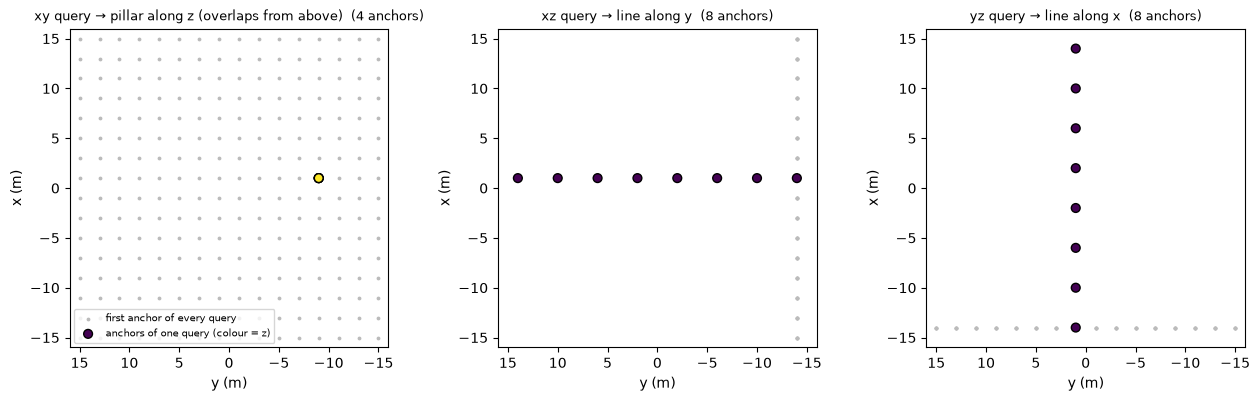

In [8]:
# Where are the 3D anchors of one query on each plane? (top view of the grid, metres)
refs = REFS
fig, axes = plt.subplots(1, 3, figsize=(13, 4), facecolor="white")
names = ["xy query → pillar along z (overlaps from above)", "xz query → line along y", "yz query → line along x"]
g = scene.grid
for plane, ax in enumerate(axes):
    anchors = refs.anchor_points(plane)                    # (Q_plane, A, 3)
    q = anchors.shape[0] // 2 + 3                          # some query near the middle
    allc = anchors[:, 0]
    ax.scatter(allc[:, 1], allc[:, 0], s=3, color="#bbbbbb", label="first anchor of every query")
    ax.scatter(anchors[q, :, 1], anchors[q, :, 0], s=40, c=anchors[q, :, 2], cmap="viridis", edgecolor="k", zorder=3,
               label="anchors of one query (colour = z)")
    ax.set_xlim(g.y_bounds[1], g.y_bounds[0]); ax.set_ylim(*g.x_bounds); ax.set_aspect("equal")
    ax.set_xlabel("y (m)"); ax.set_ylabel("x (m)"); ax.set_title(f"{names[plane]}  ({anchors.shape[1]} anchors)", fontsize=9.5)
    print(f"plane {'xy xz yz'.split()[plane]}: anchors {tuple(anchors.shape)}  one query: {anchors[q].round(decimals=1).tolist()}")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

plane xy: projected anchors (4, 4, 256, 4, 2)  visible (4, 4, 256, 4)
plane xz: projected anchors (4, 4, 64, 8, 2)  visible (4, 4, 64, 8)
plane yz: projected anchors (4, 4, 64, 8, 2)  visible (4, 4, 64, 8)


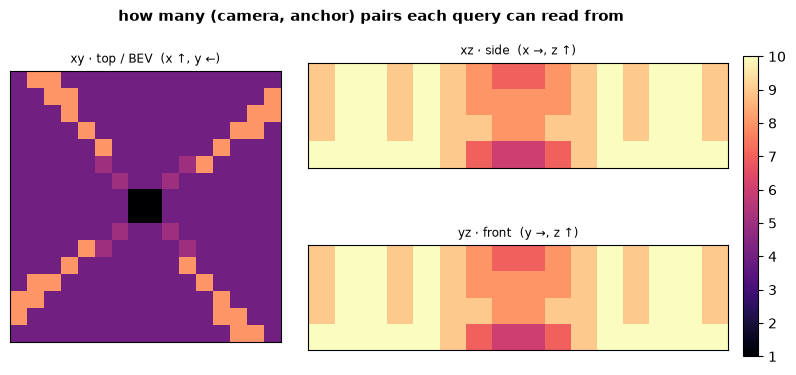

In [9]:
# Which plane cells see at least one anchor in at least one camera? (scene 0)
camera_reference = REFS.camera_reference_points(cameras)  # per plane: (B,N,Q,A,2) uv in [0,1], (B,N,Q,A) visible
seen = []
for plane, ((ref, vis), (h, w)) in enumerate(zip(camera_reference, REFS.plane_shapes)):
    print(f"plane {'xy xz yz'.split()[plane]}: projected anchors {tuple(ref.shape)}  visible {tuple(vis.shape)}")
    seen.append(vis[0].float().sum((0, 2)).view(h, w))    # (camera, anchor) hits per query
plotter.scalar_planes(seen, "how many (camera, anchor) pairs each query can read from", cmap="magma")

In [10]:
with torch.no_grad():
    native = core.lift_planes(features, cameras)          # existing method, unchanged
    projected = lifter.lift_planes(features, cameras)     # + PlaneProjection
print("TPVFormerLifter.lift_planes:", [tuple(p.shape) for p in (native.xy, native.xz, native.yz)])
print("after PlaneProjection     :", [tuple(p.shape) for p in (projected.xy, projected.xz, projected.yz)])

TPVFormerLifter.lift_planes: [(4, 32, 16, 16), (4, 32, 16, 4), (4, 32, 16, 4)]
after PlaneProjection     : [(4, 32, 16, 16), (4, 32, 16, 4), (4, 32, 16, 4)]


## 6. The triplane contract, verified

Every triplane lifter promises the same five properties (Liskov: it is still a `BaseLifter`, so it drops into
`BEVSegmentationModel`, the trainer and the verifier unchanged). `TriplaneContractChecker` runs them on real tensors.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       core = TPVFormerLifter = LIFTERS['tpvformer']
PASS  gradients reach images  1/2 pyramid levels receive gradient


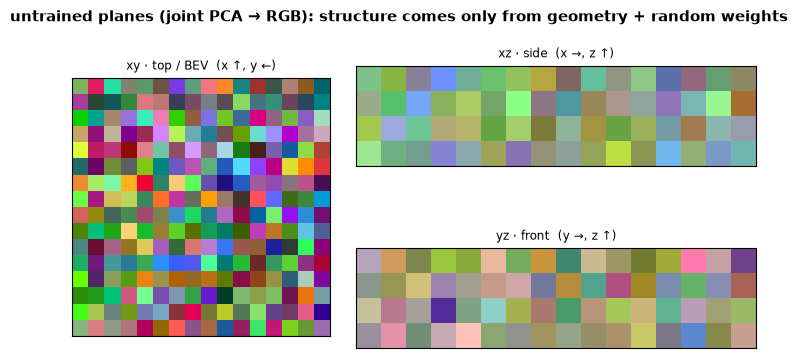

In [11]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): structure comes only from geometry + random weights")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("tpvformer", ...)` = encoder → **this triplane lifter** → `TPVAggregator` (an MLP on
`f(x,y,z) = xy + xz + yz`), plus one auxiliary classifier per plane. `OccupancyTask(aux_weight=0.5)` adds a
cross-entropy on each plane against the collapsed labels of §3. 150 AdamW steps on 128 scenes, CPU only.

lifter          params    time   before    after  corrupted   verdict
tpvformer         236k    5.1s    0.017    0.324      0.030   uses geometry


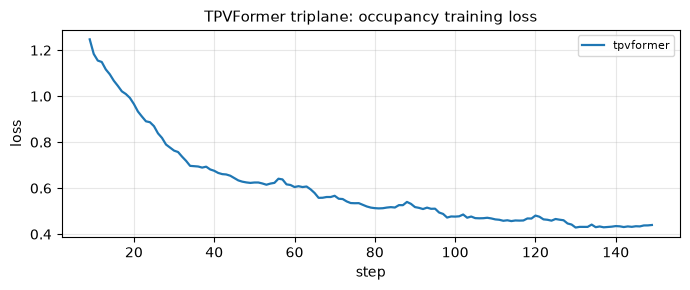

In [12]:
exp = OccupancyExperiment(scene, "tpvformer", num_layers=1)
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="TPVFormer triplane: occupancy training loss")

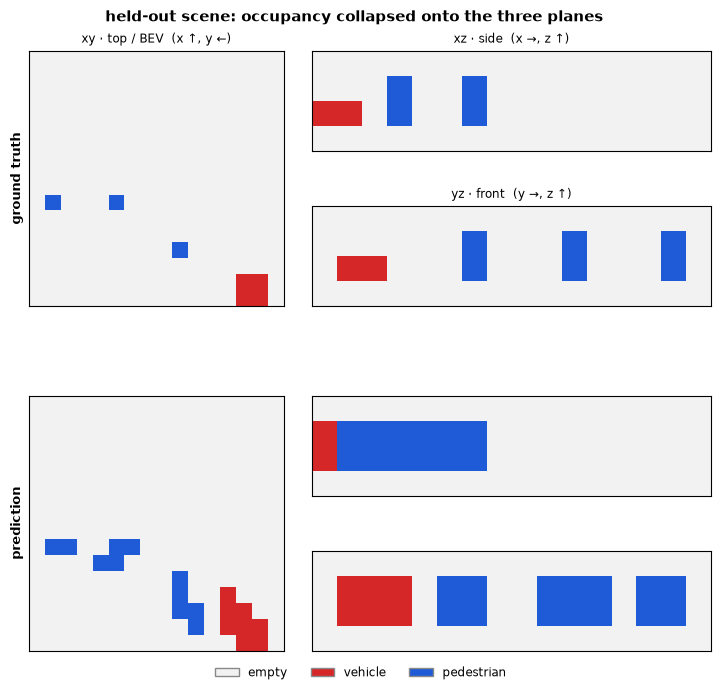

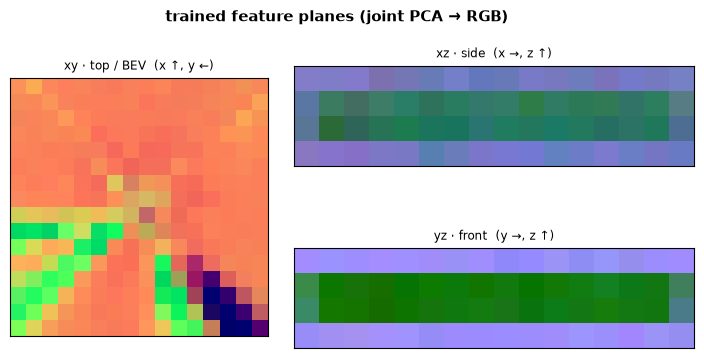

In [13]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)                       # (B, X, Y, Z) class ids
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

### Ablation: do the planes need to talk? TPVFormer vs independent planes (BEVFormer triplane)

Same anchors, same image cross-attention, same budget - the only difference is the cross-view hybrid attention.

lifter          params    time   before    after  corrupted   verdict
tpvformer         236k    5.1s    0.017    0.324      0.030   uses geometry
independent       249k    5.1s    0.008    0.295      0.030   uses geometry


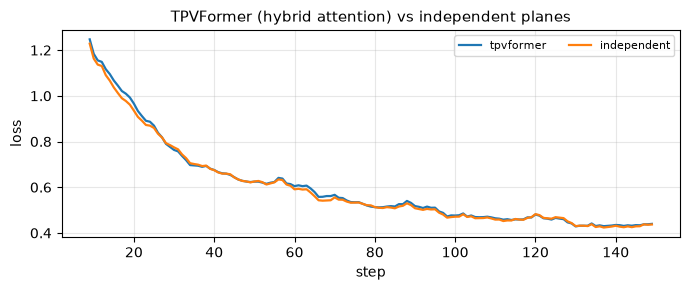

In [14]:
result_ind = OccupancyExperiment(scene, "bevformer", num_layers=1).run(steps=150)
result_ind.name = "independent"
print(ExperimentResult.header()); print(result.row()); print(result_ind.row())
OccupancyExperiment.plot_losses([result, result_ind], title="TPVFormer (hybrid attention) vs independent planes")

## 8. Negative control: does it really use the cameras?

Same images, same weights - but every camera's extrinsic is rotated by 90° about the vertical axis. A lifter that reads
pixels **through** the calibration now puts every object in the wrong place and its mIoU collapses; a geometry-free
lifter would not notice. (This is the triplane version of the repo's `lifting-verify` check.)

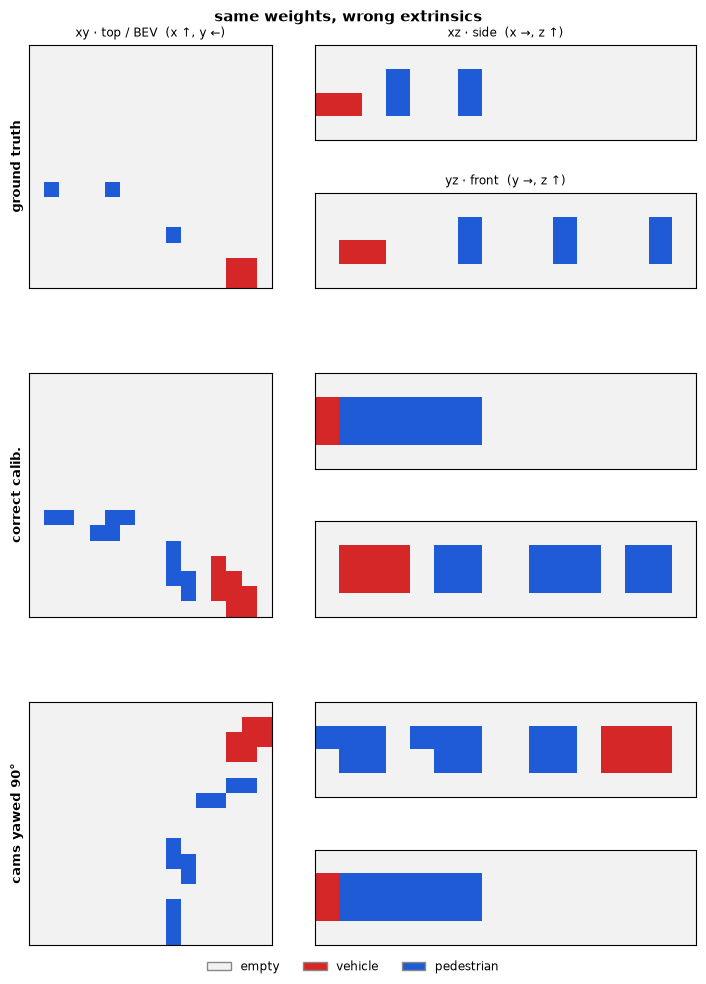

mIoU  correct calibration: 0.324   |   cameras yawed 90°: 0.030   ->  uses geometry ✅


In [15]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

# 1) just the lifter: features (B, N, C, H_l, W_l) per level + Cameras
lifter = TRIPLANE_LIFTERS.build("tpvformer", grid=grid, in_channels=64, out_channels=64, num_layers=1)
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz)
bev    = lifter(features, cameras)               # (B, 64, X, Y) - drop-in BEV lifter

# 2) 3D semantic occupancy + point queries
model = build_triplane_model("tpvformer", grid, num_classes=3, aux_heads=True, num_layers=1)
out = model(images, cameras, points=lidar_xyz)   # planes, voxel_logits, point_logits, aux_logits

# 3) BEV segmentation read off the triplane (same API as lifting.build_bev_model)
bev_model = build_triplane_bev_model("tpvformer", grid, num_classes=3, num_layers=1)
```

In [16]:
bev_model = build_triplane_bev_model("tpvformer", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16, num_layers=1)
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the triplane:", tuple(logits.shape))

BEV segmentation logits read off the triplane: (4, 3, 16, 16)


## Recap


* TPVFormer is natively triplane; the adapter only adds a per-plane projection so all lifters share one contract.
* Cross-view hybrid attention lets every token read the same 3D location on the other two planes.
* With `TriplaneOccupancyModel` you get the full TPVFormer occupancy model, now with any lifter swapped in.


**Cheat sheet**

| concept | file |
|---|---|
| TPVFormer lifter (unchanged) | `src/lifting/lifters/tpvformer/tpvformer_lifter.py` |
| layer | `src/lifting/lifters/tpvformer/tpvformer_layer.py` |
| hybrid attention | `src/lifting/attention/cross_view_hybrid_attention.py` |
| anchors + hybrid refs | `src/lifting/lifters/tpvformer/tpv_reference_points.py` |
| adapter | `src/lifting/triplane/tpvformer_triplane.py` |
| triplane contract | `src/lifting/triplane/base.py` |
| BEV read-off from planes | `src/lifting/triplane/triplane_bev_head.py` |
| occupancy model / factories | `src/lifting/triplane/triplane_occupancy_model.py`, `factory.py` |
| this animation | `src/lifting/triplane/animation/storyboards/tpvformer_storyboard.py` |

**Exercises**

1. Increase `hybrid_points` to 8. Does the gap to independent planes grow?
2. Train with `num_layers=2`; does the second layer help the `xz` / `yz` planes more than `xy`?
3. Use `exp.model(images, cameras, points=...)` to classify a vertical line of points through a pedestrian.

Next: see `00_triplane_overview.ipynb` for all techniques side by side.